<a href="https://colab.research.google.com/github/Prktriesitout/LangGraph/blob/main/Langraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

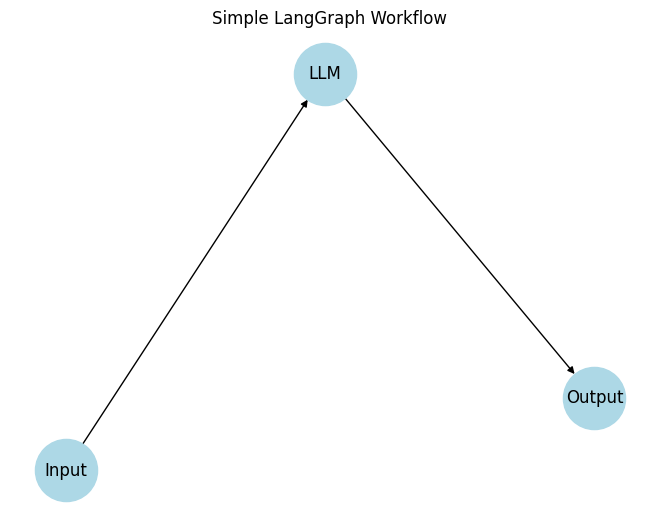

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
# Create a directed graph
G = nx.DiGraph()
# Add nodes
G.add_node("Input")
G.add_node("LLM")
G.add_node("Output")
# Add edges
G.add_edge("Input", "LLM")
G.add_edge("LLM", "Output")
# Draw the graph
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=2000, font_size=12, arrows=True)
plt.title("Simple LangGraph Workflow")
plt.show()


An Agent is a modular , autonomous entity that can perceive , reason and act based on inputs , goals and available tools .

An agent is a LLM-powered system that can
Reason : Interpret user intent and plan actions
Act : Use tools
Observe : Analyze tool ouputs
Loop : Re-plan based on feedback

Agentic AI -> introduces looping, memory and adaptive behaviour
An Agent = LLM + Tools + Reasoning Loop + State

Autonomy - operates independently , making decisions based on context and goals
Modularity - Composed of interchangeable components - LLMs. Tools, Memory, prompts
Reasoning - Uses LLMs to interpret inputs, plan actions and generate responses
Tool Use - Can invoke external tools
Memory - Maintains short-term and long-term context across interactions
Adaptablity -  Can adjust behaviour on feedback , state changes or user input



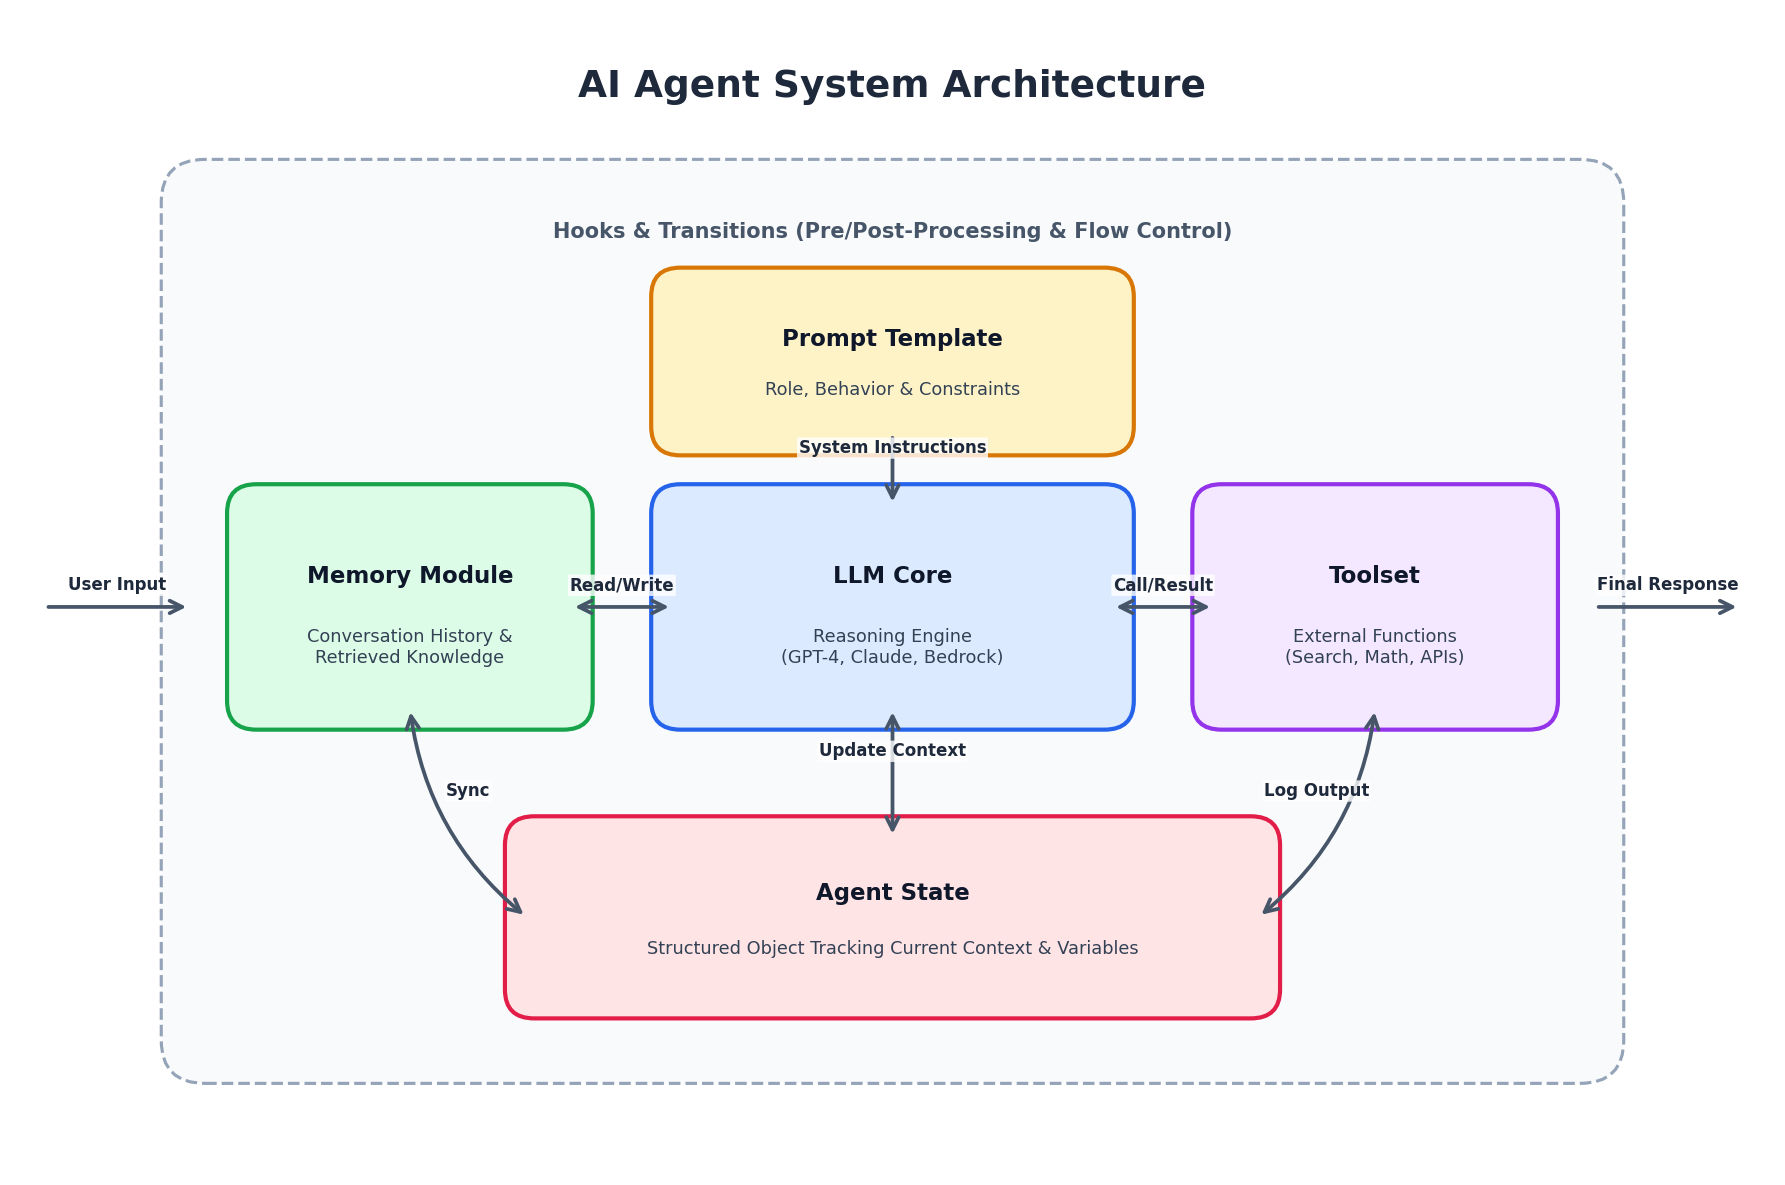

Use Cases of Agents

Customer Support Automation
Agents can triage tickets, answer FAQs and escalate complex queries
Example : A langgraph agent routes queries to domain-specific sub agents

Enterprise Knowledge Retrieval
Agents retrieve summarize and contextualize internal documents.
Example : An Agent uses RAG( Retrieval-Augmented Generation) to answer employee questions.

Research Assistance : Agents help scholars by summarizing papers, generating citations, and suggesting related work
Example : A multi-agent system with a summarizer , evaluator and optimizer

Workflow Automation : Agents orchestrate tasks across APIs, Databases and internal tools.
Example : An orchestrator agent delegates tasks to worker agents based on input types

Education & Tutoring : Agents provide personalized learning paths, answer questions and track progress
Example : A tutor agent with memory and feedback loops.

Langgraph prebuilt agent is like a starter kit . You plug in your LLM, define prompts , and optionaly add memory . It is great for tasks like document summarization , FAQ generation , or even internal ticket triage

pre_model_hook and post_model_hook , They let us inspect what the agent sees before and after the model call. it is useful for debugging and compliance checks.

We can define Schemas using Pydantic or use function calling to ensure the output is structured - like JSON with fields for summary , action items and references

Hooks are functions that allow user to intercept and inspect the flow of data before and after the node

THey are essential for:
Debugging
Logging
Monitoring
Custom pre/post-processing

Langgraph suports two main types of hooks:
pre_model_hook(state)
it allows you to inspect and modify the input state
Log incoming data
Inject additional context or metadata


In [ ]:
def pre_model_hook(state):
    print("[Pre-hook] Input to node:", state)
    state["timestamp"] = datetime.now().isoformat( )


post_model_hook(state)
This hook runs after the model or tool has executed . It allows you to:
Inspect or modify the output state
Log results
Trigger alerts or side effects

In [ ]:
def post_model_hook(state):
	print("[Post-hook] Output from node:", state)
	if "error" in state:
	send_alert(state["error"])
	return state


graph.add_pre_model_hook(pre_model_hook)
builder.add_post_model_hook(post_model_hook)


Design a single-node workflow in LangGraph where an LLM is the core action, and implement sequential pre- and post-invocation logging to audit the state (input and output) immediately before and after the LLM runs, without relying on deprecated hook methods

In [3]:
!pip install -U langchain-cohere langgraph langchain-core


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.1/588.1 kB 15.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 65.8 MB/s  0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.19
    Uninstalling langgraph-1.2.19:
      Successfully uninstalled langgraph-1.2.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [langgraph]


In [4]:
import os
from typing import TypedDict
from langchain_cohere import ChatCohere, CohereEmbeddings
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda
from langgraph.graph import END, StateGraph
from langgraph.prebuilt import ToolNode
import os
from google.colab import userdata

# Retrieve the key named 'cohere' from Colab Secrets and set it as an environment variable
os.environ["COHERE_API_KEY"] = userdata.get('cohere')

In [5]:
llm = ChatCohere(
    model = "command-a-03-2025",
    temperature = 0.5,
    max_tokens = 200,
)

class AgentState(TypedDict): #This creates a specialized python dictionary that accepts anything , this enforces strict rules on what keys exist and what data types they must hold
    """The state of the graph. We'll use a simple history of messages."""  # docstring
    messages: list[AIMessage | HumanMessage] #stores a list of the ongoing conversation . every item in this list must be an AIMessage or a HumanMessage
    question: str  #that stores the user's current query as a simple text string

In [6]:
def pre_model_hook(state: AgentState) -> AgentState:
  """Executed Before the LLM is invoked. """
  print("---Pre-Model Hook started ---")
  print(f"Input questions: {state.get('question','N/A')}")
  return state

In [7]:
def post_model_hook(state: AgentState) -> AgentState:
  """Executed After the LLM is invoked. """
  print("---Post-Model Hook started ---")
  if state.get("messages") and state["messages"][-1].content:
    print(f"LLM Response snippet: '{state['messages'][-1].content[:50]}...'")
    print("---------------------------------")
    return state

In [15]:
prompt_template = ChatPromptTemplate.from_messages([
    ("system","You are a helpful assistant. Be concise and conversational."),
    ("user", "{question}")
])

llm_runnable = prompt_template | llm

def llm_executor(state: AgentState) -> AgentState:
  """invokes the LLM and updates the state with the result."""
  question = state["question"]
  ai_message = llm_runnable.invoke({"question": question})
  new_message = state.get("messages",[]) + [ai_message]
  return {"messages": new_message, "question":question }

In [16]:
# 4. Hook the components together in a sequence
# We define a new function that represents the sequence of (Pre-Hook -> LLM Execution -> Past-Hook)

def llm_node_with_hooks(state: AgentState) -> AgentState:
  """COmbines the hooks and the LLM Execution logic sequentially."""

  state = pre_model_hook(state)
  state = llm_executor(state)
  state = post_model_hook(state)
  return state

def initial_input(state: AgentState) -> AgentState:
  """Sets the initial question and message history."""
  initial_q = "What is the capital of India and how does LangGraph work?"

  return {
       "question": initial_q,
       "messages": [HumanMessage(content=initial_q)]
   }


In [17]:
graph = StateGraph(AgentState)

graph.add_node("setup_input", initial_input)
graph.add_node("llm_and_hooks", RunnableLambda(llm_node_with_hooks))

graph.set_entry_point("setup_input")
graph.add_edge("setup_input","llm_and_hooks")
graph.add_edge("llm_and_hooks",END)

agent_graph = graph.compile()

final_state = agent_graph.invoke({})


print("n=== Final Agent Output ===")
if final_state.get("messages"):
  print(final_state["messages"][-1].content)
else:
 print("No final message was generated")

---Pre-Model Hook started ---
Input questions: What is the capital of India and how does LangGraph work?
---Post-Model Hook started ---
LLM Response snippet: 'The capital of India is **New Delhi**.

**LangGrap...'
---------------------------------
n=== Final Agent Output ===
The capital of India is **New Delhi**.

**LangGraph** is a framework designed for building **language model-powered applications** by structuring and managing the flow of data and logic. Here's how it works:

1. **Graph-Based Structure**: LangGraph uses a graph to represent the workflow of an application. Nodes in the graph represent steps or tasks (e.g., calling a language model, processing data), and edges represent the flow of data between these steps.

2. **Modular Design**: It allows you to break down complex applications into reusable components, making it easier to build, debug, and maintain.

3. **Language Model Integration**: It seamlessly integrates with language models (like OpenAI's GPT) to perform task

** Officially supported prebuilt agents **

create_react_agent :  ReAct style tool-calling
Trustcall : structured extraction / reliable tool calling
LangGraph Supervisor : For supervior / hierarchial multi agent
LangMem : long-term memory / learning from interactions
LangGraph Swarm : swarrm- style multi-agent

TrustCall : Structured data extraction with high reliablity ,
Use Cases : Extracting entities, facts or structured outputs from unstructured text


LangGraph Supervisor : Implements a supervisor multi-agent architecture
Use case : task delegation and oversight across multiple agents

LangMem : Longterm Memory management for agents
Use Case : Persistent memory across sessions or tasks

LangGraph Swarm : Swarm based multi-agent architecture

create_react_agent : Tool-calling agent using the Re-Act pattern .
Use Case : Agents that reason and act using tools

In [19]:
# how to use these Libraries

!pip install langgraph-prebuilt
from langgraph.prebuilt import create_react_agent, Trustcall, LangMem, LangGraphSupervisor, LangGraphSwarm

ImportError: cannot import name 'Trustcall' from 'langgraph.prebuilt' (/usr/local/lib/python3.13/dist-packages/langgraph/prebuilt/__init__.py)

In [21]:
# !pip install langgraph langchain-cohere
import os
from google.colab import userdata
from langchain_cohere import ChatCohere
from langgraph.prebuilt import create_react_agent

# Fetch the secret from Colab's Secrets panel (left sidebar -> key icon)
os.environ["COHERE_API_KEY"] = userdata.get("cohere")


def get_weather(city: str) -> str:
  """Get the weather for a city."""
  return f"It is sunny in {city}."


model = ChatCohere(model="command-a-03-2025")
agent = create_react_agent(model, tools=[get_weather])

result = agent.invoke(
    {"messages": [{"role": "user", "content": "Weather in Bengaluru?"}]}
)
print(result["messages"][-1].content)



/tmp/ipykernel_705/2638245579.py:17: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agent = create_react_agent(model, tools=[get_weather])


It is sunny in Bengaluru.


Langgraph prebuilt-> ready to use agent templates that encapsulates common pattern like tool usage , memory, structured output and hooks . These agents are ideal for rapid prototyping

Plug and play agents with minimal setup
Built in support for LLMs, tools and memory

Example templates :
ChatAgent -> conversational agent with memory and tool support
ToolCallingAgent : Automatically selects and invokes tools based ont user intent
StructuredOutputAgent : Ensures reponses follow a defined schema
ReflectionAgent : Evaluates its own decisions and re-plans if needed


A ReAct Style agent that follows Reason -> Act -> Observe -> Loop Pattern
ideal for building agents with tool call

weather_assistant , Return Assistant , Knowledge Agent , Structured Output Agent , Multi-Agent Supervisor
Multi-turn Chat Agent

In [22]:
import json
import os
from typing import Dict, List, Literal, TypedDict
from google.colab import userdata
from IPython.display import Image, display
# Cohere imports (replaces langchain_aws)
from langchain_cohere import ChatCohere, CohereEmbeddings
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder, PromptTemplate
from langchain_core.runnables import RunnableConfig, RunnableLambda
# LangGraph & LangChain Core imports
from langchain_core.tools import tool
from langgraph.graph import END, MessagesState, START, StateGraph
from langgraph.prebuilt import ToolNode, create_react_agent

# Load API key from Google Colab Secrets
os.environ["COHERE_API_KEY"] = userdata.get("cohere")


In [23]:
llm = ChatCohere(
    model="command-a-03-2025",  # Or "command-r-plus-08-2024" for direct Command R+
    temperature=0.5,
    max_tokens=50,
)


In [24]:
@tool
def get_weather(city: str) -> str:
    """Return a one-line weather summary for 'city'."""
    # Replace this with real API call in production
    fake = {
        "Mysore": "23°C, partly cloudy",
        "New Delhi": "32°C, hot and humid",
        "Bangalore": "25°C, foggy"
    }
    return f"Weather in {city}: {fake.get(city, '20°C, clear skies')}"
@tool
def find_attractions(city: str) -> str:
    """Return a short list of top attractions for the city in JSON string form."""
    # Real implementation should call a places API and return structured data.
    attractions = {
        "Mysore": [
            {"name": "Mysore Palace", "type": "Hostorical", "visit_time_mins": 90},
            {"name": "Mysore Zoo", "type": "Zooloy", "visit_time_mins": 120},
            {"name": "Sand Meuseum", "type": "museum", "visit_time_mins": 60},
        ],
        "Bangalore": [
            {"name": "LalBagh", "type": "entertainment", "visit_time_mins": 60},
            {"name": "Planitorium", "type": "Education", "visit_time_mins": 90},
        ]
    }
    res = attractions.get(city, [])
    return json.dumps(res)
@tool
def get_directions(origin: str, destination: str) -> str:
    """Return a short route summary."""
    # Replace with call to directions API for real routing information.
    return f"Route from {origin} to {destination}: Drive ~30 mins (20 km) via Main St."
tools = [get_weather, find_attractions, get_directions]


In [25]:
tools_by_name = { tool.name: tool for tool in tools}
model_with_tools = llm.bind_tools(tools)



In [26]:
def call_llm(state: MessagesState):
    messages = [SystemMessage(content="You are a helpful assistant to suggest weather and attraction of the given Place."),] + state["messages"]
    return {"messages": [model_with_tools.invoke(messages)]}
def call_tool(state: MessagesState):
    result = []
    for tool_call in state["messages"][-1].tool_calls:
        tool = tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        result.append(ToolMessage(content=observation, tool_call_id=tool_call["id"]))
    return {"messages": result}
def should_continue(state: MessagesState) -> Literal["environment", END]:
    messages = state["messages"]
    last_message = messages[-1]
    if last_message.tool_calls:
        return "Action"
    return END



In [27]:
graph = StateGraph(MessagesState)
graph.add_node("llm", call_llm)
graph.add_node("environment", call_tool)
graph.add_edge(START, "llm")
graph.add_conditional_edges("llm",  should_continue, { "Action": "environment", END: END,},)
graph.add_edge("environment", "llm")
agent = graph.compile()


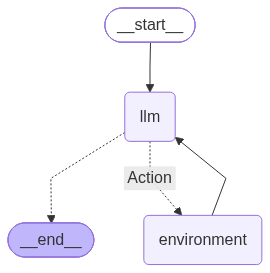

In [28]:
display(Image(agent.get_graph(xray=True).draw_mermaid_png()))


In [29]:
messages = [
    SystemMessage(content="You are a helpful  assistant to suggest weather and attractions"),
    HumanMessage(content="I want to plan a travel to Mysore"),
]
messages = agent.invoke({"messages": messages})
for m in messages["messages"]:
    m.pretty_print()


================================ System Message ================================

You are a helpful  assistant to suggest weather and attractions
================================ Human Message =================================

I want to plan a travel to Mysore
================================== Ai Message ==================================

I will use the find_attractions tool to find the top attractions in Mysore. I will also use the get_weather tool to find the weather in Mysore.
Tool Calls:
  find_attractions (find_attractions_6zdtjfgesy57)
 Call ID: find_attractions_6zdtjfgesy57
  Args:
    city: Mysore
  get_weather (get_weather_kbekgmyrrv46)
 Call ID: get_weather_kbekgmyrrv46
  Args:
    city: Mysore
================================= Tool Message =================================

[{"name": "Mysore Palace", "type": "Hostorical", "visit_time_mins": 90}, {"name": "Mysore Zoo", "type": "Zooloy", "visit_time_mins": 120}, {"name": "Sand Meuseum", "type": "museum", "visit_time_mins": 

In [30]:
 !pip install langchain-experimental
 !pip install feedparser


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 40.1 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [langchain-experimental]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [feedparser]


KeyboardInterrupt: 

In [ ]:
from typing import List, Dict, Optional
from urllib.parse import quote
import feedparser
class GoogleNews:
    def _fetch_news(self, url: str, k: int = 3) -> List[Dict[str, str]]:
        news_data = feedparser.parse(url)
        return [
            {"title": entry.title, "link": entry.link}
            for entry in news_data.entries[:k]
        ]
    def _collect_news(self, news_list: List[Dict[str, str]]) -> List[Dict[str, str]]:
        if not news_list:
            print("There is no news for the keyword.")
            return []
        result = []
        for news in news_list:
            result.append({"url": news["link"], "content": news["title"]})
        return result
    def search_by_keyword(
        self, keyword: Optional[str] = None, k: int = 3
    ) -> List[Dict[str, str]]:
        if keyword:
            encoded_keyword = quote(keyword)
            url = f"https://news.google.com/rss/search?q={encoded_keyword}&hl=en&gl=US&ceid=US:en"
        else:
            url = f"https://news.google.com/rss?hl=en&gl=US&ceid=US:en"
        news_list = self._fetch_news(url, k)
        return self._collect_news(news_list)


In [ ]:
@tool
def search_news(query: str) -> List[Dict[str, str]]:
    """Search Google News by input keyword"""
    news = GoogleNews()
    return news.search_by_keyword(query, k=5)
@tool
def python_code_interpreter(code: str):
    """Call to execute python code."""
    return PythonAstREPLTool().invoke(code)


In [ ]:
from langgraph.prebuilt import ToolNode, tools_condition
# Generate tool list
tools = [search_news, python_code_interpreter]
# Initialize ToolNode
tool_node = ToolNode(tools, handle_tool_errors=True)


In [ ]:
from langchain_core.messages import AIMessage
# Creating an AI message object with single tool call
message_with_single_tool_call = AIMessage(
    content="",
    tool_calls=[
        {
            "name": "search_news",
            "args": {"query": "Tesla new model"},
            "id": "tool_call_id",
            "type": "tool_call",
        }
    ],
)
# Invoke single tool call with created message
tool_node.invoke({"messages": [message_with_single_tool_call]})


In [ ]:
# Creating an AI message object with multiple tool calls
message_with_multiple_tool_calls = AIMessage(
    content="",
    tool_calls=[
        {
            "name": "search_news",
            "args": {"query": "Tesla new model"},
            "id": "tool_call_id_1",
            "type": "tool_call",
        },
        {
            "name": "python_code_interpreter",
            "args": {"code": "print(1+2+3+4)"},
            "id": "tool_call_id_2",
            "type": "tool_call",
        },
    ],
)
# Invoke multiple tool calls with created message
tool_node.invoke({"messages": [message_with_multiple_tool_calls]})


In [ ]:
tools_by_name = {tool.name: tool for tool in tools}
# Initialize LLM model and bind tools
model_with_tools = llm.bind_tools(tools)


In [ ]:
response = model_with_tools.invoke( "Write Python code to print the first 5 prime numbers.")
print(response)
print(response.tool_calls)


**Langgraph-Supervisor**

In [2]:
!pip install -U langgraph langgraph-supervisor langchain-cohere

In [3]:
import os
from google.colab import userdata
from langchain_cohere import ChatCohere, CohereEmbeddings
from langgraph.prebuilt import create_react_agent
from langgraph_supervisor import create_supervisor

# Fetch your secret named "cohere" from Google Colab Secrets
os.environ["COHERE_API_KEY"] = userdata.get("cohere")

# ---------------------------
# Cohere LLM Setup
# ---------------------------
llm = ChatCohere(
    model="command-a-03-2025",  # Or "command-r-plus-08-2024"
    temperature=0.5,
    max_tokens=50,
)


In [7]:
from cohere import ToolV2


# Complete patch so LangGraph / langgraph-supervisor can read ToolV2 like a dict
def _toolv2_getitem(self, key):
  if key == "function" and isinstance(self.function, dict):
    return self.function
  val = getattr(self, key)
  return val.model_dump() if hasattr(val, "model_dump") else val


ToolV2.get = lambda self, key, default=None: getattr(self, key, default)
ToolV2.__getitem__ = _toolv2_getitem


In [8]:
# Step 2: Define tools for each agent
def book_hotel(hotel_name: str):
    """you are helpful assistant for Hotel Booking"""
    return f"Hotel booked at {hotel_name}."
def book_flight(from_airport: str, to_airport: str):
    """you are helpful assistant for Flight Booking"""
    return f"Flight booked from {from_airport} to {to_airport}."
# Step 3: Create agents
flight_agent = create_react_agent(
    model=llm,
    tools=[book_flight],
    prompt="You are a flight booking assistant.",
    name="flight_assistant"
)
hotel_agent = create_react_agent(
    model=llm,
    tools=[book_hotel],
    prompt="You are a hotel booking assistant.",
    name="hotel_assistant"
)
# Step 4: Create the supervisor
supervisor = create_supervisor(
    agents=[flight_agent, hotel_agent],
    model=llm,
    prompt="You manage a flight and hotel booking assistant. Assign tasks accordingly."
).compile()
# Step 5: Run the supervisor with a user message
user_input = {
    "messages": [
        {"role": "user", "content": "Book a flight from BOS to JFK and a stay at McKittrick Hotel"}
    ]
}
# Step 6: Stream the response
for step in supervisor.stream(user_input):
    print(step, "\n")


/tmp/ipykernel_33957/2975870345.py:9: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  flight_agent = create_react_agent(
/tmp/ipykernel_33957/2975870345.py:15: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  hotel_agent = create_react_agent(


{'supervisor': None} 

{'flight_assistant': {'messages': [AIMessage(content='Successfully transferred to flight_assistant.', additional_kwargs={'id': 'b30bcc0e-d812-4839-aa8e-1da7d62bc5dd', 'finish_reason': 'COMPLETE', 'citations': [Citation(start=0, end=45, text='Successfully transferred to flight_assistant.', sources=[ToolSource(type='tool', id='transfer_to_flight_assistant_hjaq9rcdgmfr:0', tool_output={'output': 'Successfully transferred to flight_assistant'})], content_index=None, type='TEXT_CONTENT')], 'token_count': {'input_tokens': 1645.0, 'output_tokens': 20.0}}, response_metadata={'id': 'b30bcc0e-d812-4839-aa8e-1da7d62bc5dd', 'finish_reason': 'COMPLETE', 'citations': [Citation(start=0, end=45, text='Successfully transferred to flight_assistant.', sources=[ToolSource(type='tool', id='transfer_to_flight_assistant_hjaq9rcdgmfr:0', tool_output={'output': 'Successfully transferred to flight_assistant'})], content_index=None, type='TEXT_CONTENT')], 'token_count': {'input_tokens': 16